# BOS Flight Visualization

**Scope of Study:** Domestic flight departing from BOS, as reported to the BTS by airlines, covering the period from 2022 to 2025.
International flights arriving at BOS are excluded; data for 2026 is reserved for final testing.
An arrival delay is defined as a delay of **at least 15 minutes** (labeled as `ArrDel15`).

In [9]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

project_folder = Path(r"C:\Users\mengk\OneDrive\文档\大四\CS 506\Final Project")
data_file = project_folder / "data" / "processed_basic" / "actual_weather_2022_2025.csv"
picture_folder = project_folder / "figures" / "visualization_learning"

minimum_hour_count = 1000

## Delay Rate

In [10]:
# Read the data and filter it
columns = [
    "FlightDate", "Month", "DepHour", "ArrDel15",
    "Cancelled", "Diverted", "ActualVisibility", "ActualWind"
]
data = pd.read_csv(data_file, usecols=columns)
data["FlightDate"] = pd.to_datetime(data["FlightDate"])


data = data[data["FlightDate"] >= "2022-01-01"].copy()
data = data[data["FlightDate"] < "2026-01-01"].copy()
delay_flights = data[data["Cancelled"] == 0].copy()
delay_flights = delay_flights[delay_flights["Diverted"] == 0].copy()
delay_flights = delay_flights[delay_flights["ArrDel15"].isin([0, 1])].copy()

total_flights = len(delay_flights)
delayed_flights = delay_flights["ArrDel15"].sum()
delay_percent = delayed_flights / total_flights * 100

print("Total number of flights:", len(data))
print("Delayed flights:", delayed_flights)
print("Overall delay rate (%):", round(delay_percent, 2))
data.head()

Total number of flights: 563342
Delayed flights: 122971.0
Overall delay rate (%): 22.35


,Month,FlightDate,ArrDel15,Cancelled,Diverted,DepHour,ActualWind,ActualVisibility
0,1,2022-01-01,0.0,0.0,0.0,5,5.0,0.25
1,1,2022-01-01,0.0,0.0,0.0,5,5.0,0.25
2,1,2022-01-01,0.0,0.0,0.0,5,5.0,0.25
3,1,2022-01-01,0.0,0.0,0.0,5,5.0,0.25
4,1,2022-01-01,0.0,0.0,0.0,5,5.0,0.25


## Monthly Chart: Calculate the Figures First

**Question: Which months have higher arrival delay rates?**

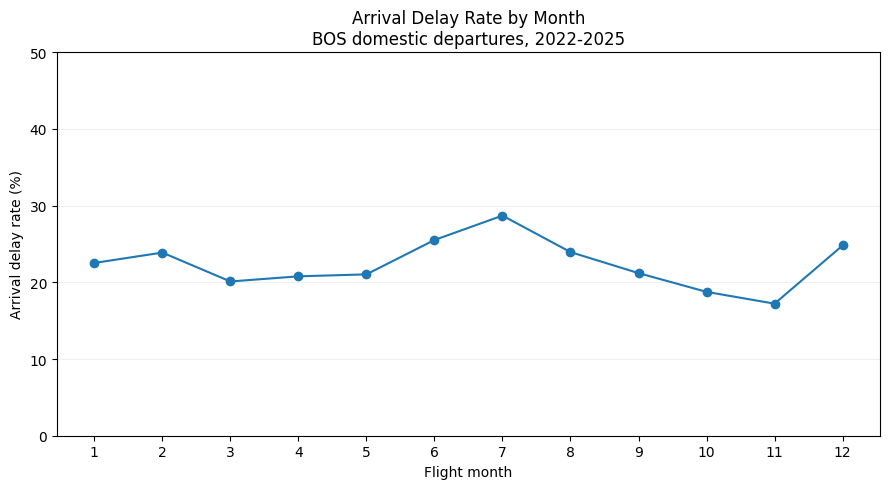

In [11]:
month_rows = []

for month in range(1, 13):
    month_flights = delay_flights[delay_flights["Month"] == month]
    total = len(month_flights)
    delayed = month_flights["ArrDel15"].sum()
    percent = delayed / total * 100
    month_rows.append([month, total, delayed, percent])

month_table = pd.DataFrame(
    month_rows,
    columns=["Month", "TotalFlights", "DelayedFlights", "DelayPercent"]
)

month_table.round(2)

picture_folder.mkdir(parents=True, exist_ok=True)

plt.figure(figsize=(9, 5))
plt.plot(month_table["Month"], month_table["DelayPercent"], marker="o")
plt.xticks(range(1, 13))
plt.ylim(0, 50)
plt.xlabel("Flight month")
plt.ylabel("Arrival delay rate (%)")
plt.title("Arrival Delay Rate by Month\nBOS domestic departures, 2022-2025")
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()

month_table.to_csv(picture_folder / "month_summary.csv", index=False)
plt.savefig(picture_folder / "01_month.png", dpi=200)
plt.show()

## Visibility Chart

**Question: How does the arrival delay rate vary under different actual visibility conditions?**

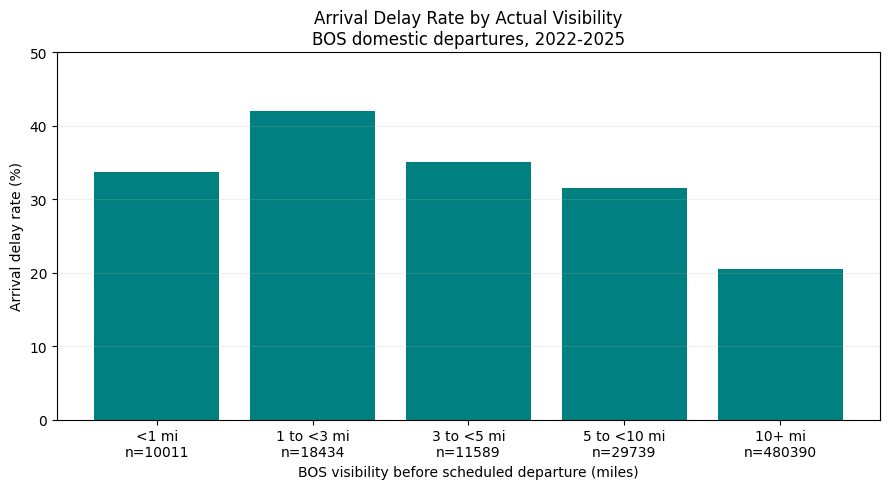

In [12]:
visibility_below_1 = delay_flights[delay_flights["ActualVisibility"] < 1]

visibility_1_to_3 = delay_flights[(delay_flights["ActualVisibility"] >= 1) & (delay_flights["ActualVisibility"] < 3)]

visibility_3_to_5 = delay_flights[(delay_flights["ActualVisibility"] >= 3) & (delay_flights["ActualVisibility"] < 5)]

visibility_5_to_10 = delay_flights[(delay_flights["ActualVisibility"] >= 5) & (delay_flights["ActualVisibility"] < 10)]

visibility_10_plus = delay_flights[delay_flights["ActualVisibility"] >= 10]

visibility_groups = [
    visibility_below_1, visibility_1_to_3, visibility_3_to_5,
    visibility_5_to_10, visibility_10_plus
]
visibility_names = ["<1 mi", "1 to <3 mi", "3 to <5 mi", "5 to <10 mi", "10+ mi"]
visibility_rows = []
visibility_plot_names = []

for i in range(5):
    group = visibility_groups[i]
    total = len(group)
    delayed = group["ArrDel15"].sum()
    percent = delayed / total * 100
    visibility_rows.append([visibility_names[i], total, delayed, percent])
    visibility_plot_names.append(visibility_names[i] + "\nn=" + str(total))

visibility_table = pd.DataFrame(
    visibility_rows,
    columns=["Visibility", "TotalFlights", "DelayedFlights", "DelayPercent"]
)
visibility_table.round(2)

plt.figure(figsize=(9, 5))
plt.bar(visibility_plot_names, visibility_table["DelayPercent"], color="teal")
plt.ylim(0, 50)
plt.xlabel("BOS visibility before scheduled departure (miles)")
plt.ylabel("Arrival delay rate (%)")
plt.title("Arrival Delay Rate by Actual Visibility\nBOS domestic departures, 2022-2025")
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()

visibility_table.to_csv(picture_folder / "visibility_summary.csv", index=False)
plt.savefig(picture_folder / "02_visibility.png", dpi=200)
plt.show()

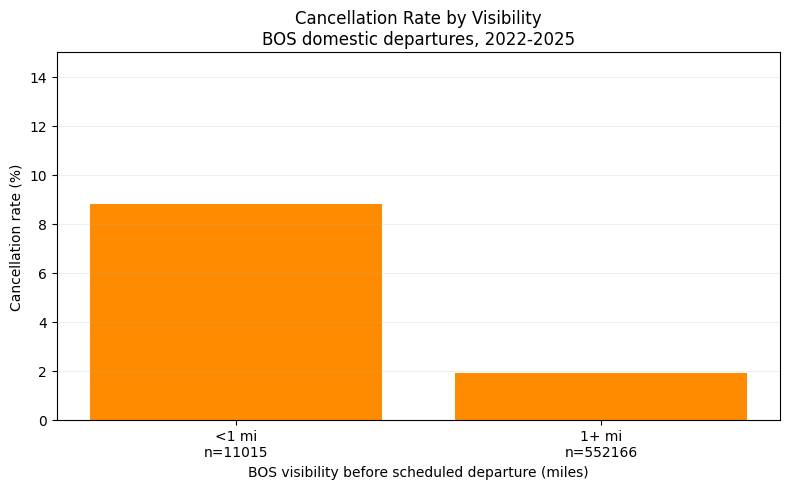

In [13]:
cancel_data = data[data["Cancelled"].isin([0, 1])].copy()
cancel_low = cancel_data[cancel_data["ActualVisibility"] < 1]
cancel_other = cancel_data[cancel_data["ActualVisibility"] >= 1]

low_total = len(cancel_low)
low_cancelled = cancel_low["Cancelled"].sum()
low_percent = low_cancelled / low_total * 100

other_total = len(cancel_other)
other_cancelled = cancel_other["Cancelled"].sum()
other_percent = other_cancelled / other_total * 100

cancel_table = pd.DataFrame(
    [
        ["<1 mi", low_total, low_cancelled, low_percent],
        ["1+ mi", other_total, other_cancelled, other_percent]
    ],
    columns=["Visibility", "TotalFlights", "CancelledFlights", "CancelPercent"]
)
cancel_table.round(2)

# 两个横轴标签分别拼上对应的有效样本数。
cancel_plot_names = ["<1 mi\nn=" + str(low_total), "1+ mi\nn=" + str(other_total)]

plt.figure(figsize=(8, 5))
plt.bar(cancel_plot_names, cancel_table["CancelPercent"], color="darkorange")
plt.ylim(0, 15)
plt.xlabel("BOS visibility before scheduled departure (miles)")
plt.ylabel("Cancellation rate (%)")
plt.title("Cancellation Rate by Visibility\nBOS domestic departures, 2022-2025")
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()

cancel_table.to_csv(picture_folder / "cancellation_summary.csv", index=False)
plt.savefig(picture_folder / "05_cancellation_optional.png", dpi=200)
plt.show()

## Wind Speed ​​Chart

**Question: How does the arrival delay rate vary under different actual wind speeds?**

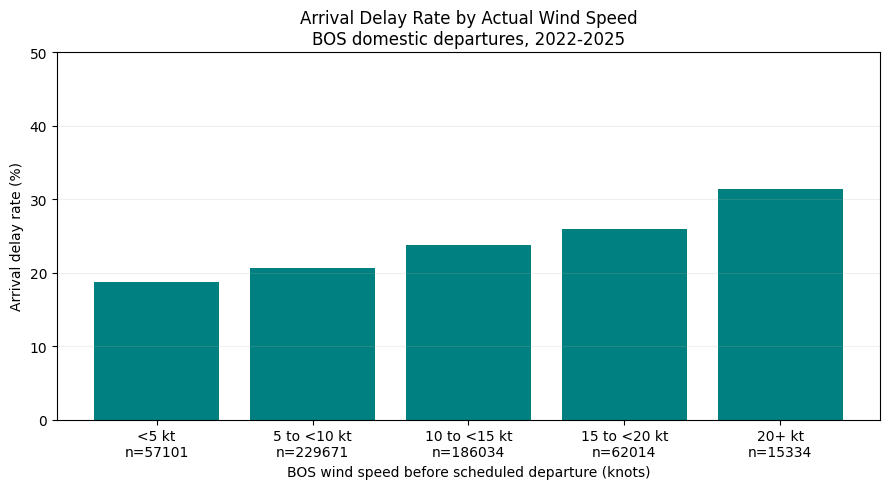

In [14]:
wind_below_5 = delay_flights[delay_flights["ActualWind"] < 5]

wind_5_to_10 = delay_flights[(delay_flights["ActualWind"] >= 5) & (delay_flights["ActualWind"] < 10)]

wind_10_to_15 = delay_flights[(delay_flights["ActualWind"] >= 10) & (delay_flights["ActualWind"] < 15)]

wind_15_to_20 = delay_flights[(delay_flights["ActualWind"] >= 15) & (delay_flights["ActualWind"] < 20)]

wind_20_plus = delay_flights[delay_flights["ActualWind"] >= 20]

wind_groups = [wind_below_5, wind_5_to_10, wind_10_to_15, wind_15_to_20, wind_20_plus]
wind_names = ["<5 kt", "5 to <10 kt", "10 to <15 kt", "15 to <20 kt", "20+ kt"]
wind_rows = []
wind_plot_names = []

for i in range(5):
    group = wind_groups[i]
    total = len(group)
    delayed = group["ArrDel15"].sum()
    percent = delayed / total * 100
    wind_rows.append([wind_names[i], total, delayed, percent])
    wind_plot_names.append(wind_names[i] + "\nn=" + str(total))

wind_table = pd.DataFrame(
    wind_rows,
    columns=["WindSpeed", "TotalFlights", "DelayedFlights", "DelayPercent"]
)
wind_table.round(2)

plt.figure(figsize=(9, 5))
plt.bar(wind_plot_names, wind_table["DelayPercent"], color="teal")
plt.ylim(0, 50)
plt.xlabel("BOS wind speed before scheduled departure (knots)")
plt.ylabel("Arrival delay rate (%)")
plt.title("Arrival Delay Rate by Actual Wind Speed\nBOS domestic departures, 2022-2025")
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()

wind_table.to_csv(picture_folder / "wind_summary.csv", index=False)
plt.savefig(picture_folder / "03_wind.png", dpi=200)
plt.show()

## Scheduled Departure Hour Chart

**Question: Which scheduled departure time slots throughout the day are associated with higher arrival delay rates?**

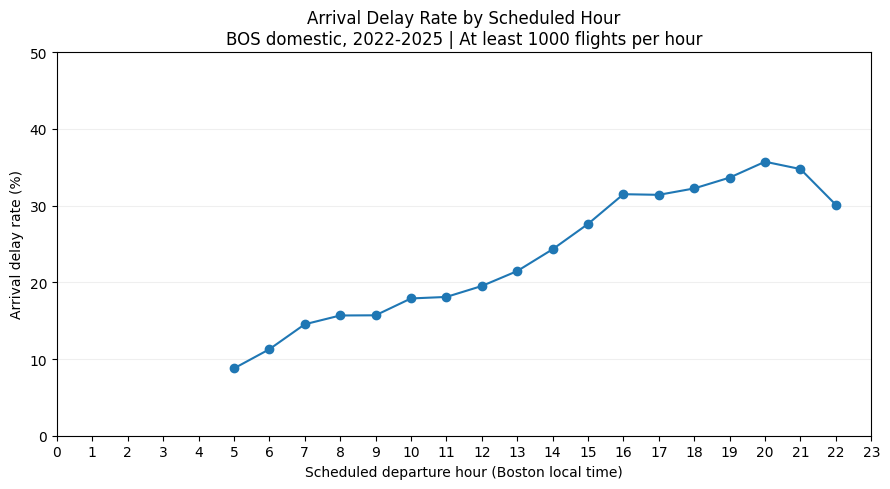

In [15]:
hour_rows = []
hour_plot_rates = []

for hour in range(24):
    hour_flights = delay_flights[delay_flights["DepHour"] == hour]
    total = len(hour_flights)
    delayed = hour_flights["ArrDel15"].sum()

    if total > 0:
        percent = delayed / total * 100
    else:
        percent = None

    hour_rows.append([hour, total, delayed, percent])

    if total >= minimum_hour_count:
        hour_plot_rates.append(percent)
    else:
        hour_plot_rates.append(None)

hour_table = pd.DataFrame(
    hour_rows,
    columns=["DepHour", "TotalFlights", "DelayedFlights", "DelayPercent"]
)
hour_table.round(2)

plt.figure(figsize=(9, 5))
plt.plot(range(24), hour_plot_rates, marker="o")
plt.xticks(range(24))
plt.ylim(0, 50)
plt.xlabel("Scheduled departure hour (Boston local time)")
plt.ylabel("Arrival delay rate (%)")
plt.title("Arrival Delay Rate by Scheduled Hour\nBOS domestic, 2022-2025 | At least " + str(minimum_hour_count) + " flights per hour")
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()

hour_table.to_csv(picture_folder / "hour_summary_all.csv", index=False)
plt.savefig(picture_folder / "04_hour.png", dpi=200)
plt.show()